# **Import Library**

In [185]:
import pandas as pd  # Pandas untuk manipulasi dan analisis data
pd.options.mode.chained_assignment = None  # Menonaktifkan peringatan chaining
import numpy as np  # NumPy untuk komputasi numerik
seed = 0
np.random.seed(seed)  # Mengatur seed untuk reproduktibilitas
import matplotlib.pyplot as plt  # Matplotlib untuk visualisasi data
import seaborn as sns  # Seaborn untuk visualisasi data statistik, mengatur gaya visualisasi
from sklearn.metrics import accuracy_score

import datetime as dt  # Manipulasi data waktu dan tanggal
import re  # Modul untuk bekerja dengan ekspresi reguler
import string  # Berisi konstanta string, seperti tanda baca
from nltk.tokenize import word_tokenize  # Tokenisasi teks
from nltk.corpus import stopwords  # Daftar kata-kata berhenti dalam teks

!pip install sastrawi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory  # Stemming (penghilangan imbuhan kata) dalam bahasa Indonesia
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory  # Menghapus kata-kata berhenti dalam bahasa Indonesia

from wordcloud import WordCloud  # Membuat visualisasi berbentuk awan kata (word cloud) dari teks

import nltk  # Import pustaka NLTK (Natural Language Toolkit).
nltk.download('punkt')  # Mengunduh dataset yang diperlukan untuk tokenisasi teks.
nltk.download('stopwords')  # Mengunduh dataset yang berisi daftar kata-kata berhenti (stopwords) dalam berbagai bahasa.

import csv #membaca file CSV dari hasil scraping
import requests #mengambil file CSV leksikon sentimen dari GitHub
from io import StringIO # Mengubah string menjadi objek seperti file
from sklearn.model_selection import train_test_split # Membagi dataset menjadi data latih dan data uji
from sklearn.naive_bayes import BernoulliNB # Algoritma Naive Bayes
from sklearn.ensemble import RandomForestClassifier # Algoritma Random Forest
from sklearn.linear_model import LogisticRegression # Model klasifikasi Logistic Regression
from sklearn.tree import DecisionTreeClassifier # Model Decision Tree
from sklearn.svm import SVC # Model SVM
from sklearn.metrics import classification_report # Mengevaluasi model dengan precision, recall, f1-score, dan akurasi secara menyeluruh setelah model diuji.
from gensim.models import Word2Vec # Membangun representasi vektor kata (word embedding)
from sklearn.feature_extraction.text import TfidfVectorizer # Mengubah teks menjadi fitur numerik berbasis TF-IDF

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# **LOADING DATASET**

In [186]:
data = pd.read_csv('hasil_scraper_ulasan_app_instagram.csv')

In [187]:
df = pd.DataFrame(data)
df.head()

,Review ID,Rating,Review Text,Date
0,cac788ca-6506-4451-9e70-4b84a66f9b8e,4,Instagram Tuti Wahyuni,2025-04-09 11:48:30
1,6e67c75b-22f8-4774-892d-636e29808fd6,5,muhammad Ayib ALKAFF MUHAMM AYIB ALKAFF,2025-04-09 08:50:48
2,b9ddaa0e-2f8f-4c8d-a68a-28003b48e1e6,1,tidak bisa login,2025-04-09 06:50:54
3,731aa75e-821f-4851-8537-2c4e8282411c,5,Kenapa ig tdk bisa menginstal,2025-04-09 06:35:54
4,6e978195-dda1-4ef4-965e-79e3bab15570,1,kenapa nyari filter gabisa tulisannya tidak da...,2025-04-09 03:41:05


In [188]:
df.shape

(10000, 4)

In [189]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Review ID    10000 non-null  object
 1   Rating       10000 non-null  int64 
 2   Review Text  10000 non-null  object
 3   Date         10000 non-null  object
dtypes: int64(1), object(3)
memory usage: 312.6+ KB


# **PREPROCESSING DATA**

In [190]:
#Mengecek apakah terdapat missing value
missing_value = df.isnull().sum()
print(missing_value)

Review ID      0
Rating         0
Review Text    0
Date           0
dtype: int64


In [191]:
print("Jumlah duplikasi: ", df.duplicated().sum())

Jumlah duplikasi:  0


In [192]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Review ID    10000 non-null  object
 1   Rating       10000 non-null  int64 
 2   Review Text  10000 non-null  object
 3   Date         10000 non-null  object
dtypes: int64(1), object(3)
memory usage: 312.6+ KB


In [193]:
# Mengubah kolom 'Date' menjadi tipe data datetime
df['Date'] = pd.to_datetime(df['Date'])

# Mengubah format kolom 'Date' menjadi hanya tanggal, bulan, dan tahun (DD-MM-YYYY)
df['Date'] = df['Date'].dt.strftime('%d-%m-%Y')

# Menampilkan hasil untuk memastikan perubahan
print(df.head())

                              Review ID  Rating  \
0  cac788ca-6506-4451-9e70-4b84a66f9b8e       4   
1  6e67c75b-22f8-4774-892d-636e29808fd6       5   
2  b9ddaa0e-2f8f-4c8d-a68a-28003b48e1e6       1   
3  731aa75e-821f-4851-8537-2c4e8282411c       5   
4  6e978195-dda1-4ef4-965e-79e3bab15570       1   

                                         Review Text        Date  
0                             Instagram Tuti Wahyuni  09-04-2025  
1            muhammad Ayib ALKAFF MUHAMM AYIB ALKAFF  09-04-2025  
2                                   tidak bisa login  09-04-2025  
3                      Kenapa ig tdk bisa menginstal  09-04-2025  
4  kenapa nyari filter gabisa tulisannya tidak da...  09-04-2025  


In [194]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Review ID    10000 non-null  object
 1   Rating       10000 non-null  int64 
 2   Review Text  10000 non-null  object
 3   Date         10000 non-null  object
dtypes: int64(1), object(3)
memory usage: 312.6+ KB


# **PREPROCESSING TEXT**

In [195]:
def cleaningText(text):
    if not text:
        return ""
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)  # mention
    text = re.sub(r'#[A-Za-z0-9_]+', '', text)  # hashtag
    text = re.sub(r'\brt\b', '', text, flags=re.IGNORECASE)  # RT
    text = re.sub(r"http\S+|www.\S+", '', text)  # links
    text = re.sub(r'\d+', '', text)  # angka
    text = re.sub(r'[^\w\s]', '', text)  # karakter khusus

    text = text.replace('\n', ' ')
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text.strip()

def casefoldingText(text):
    if not text:
        return ""
    return text.lower()

def tokenizingText(text):
    try:
        return word_tokenize(text)
    except:
        return text.split()

def filteringText(text, custom_stopwords=None):
    if not isinstance(text, list):
        return []
    listStopwords = set(stopwords.words('indonesian') + stopwords.words('english'))
    additional_stopwords = ['iya','yaa','gak','nya','na','sih','ku',"di","ga","ya","gaa","loh","kah","woi","woii","woy"]
    if custom_stopwords:
        listStopwords.update(custom_stopwords)
    listStopwords.update(additional_stopwords)
    return [word for word in text if word not in listStopwords]

def stemmingText(text):
    if not text:
        return ""
    try:
        factory = StemmerFactory()
        stemmer = factory.create_stemmer()
        words = text.split()
        return ' '.join([stemmer.stem(word) for word in words])
    except:
        return text

def toSentence(list_words):
    if not isinstance(list_words, list):
        return str(list_words)
    return ' '.join(list_words)

In [196]:
# Kamus slang word default
default_slangwords = {
    "@": "di", "abis": "habis", "wtb": "beli", "masi": "masih", "wts": "jual",
    "wtt": "tukar", "bgt": "banget", "maks": "maksimal", "gk": "tidak",
    "ga": "tidak", "tdk": "tidak", "tp": "tapi", "yg": "yang", "dgn": "dengan",
    "krn": "karena", "lg": "lagi", "bisa": "bisa", "gabisa": "tidak bisa",
    "udh": "sudah", "sm": "sama", "aja": "saja", "blm": "belum", "nyari": "mencari"
}

# Fungsi mengganti slang word
def fix_slangwords(text, slangwords_dict=None):
    if not isinstance(text, str):
        return ""

    slang_dict = default_slangwords.copy()
    if slangwords_dict:
        slang_dict.update(slangwords_dict)  # Tambahkan slang custom jika ada

    words = re.findall(r'\b\w+\b', text.lower())  # Ambil kata tanpa tanda baca
    fixed_words = [slang_dict.get(word, word) for word in words]

    return ' '.join(fixed_words)

# Contoh penggunaan di dataframe
df['Cleaned Review'] = df['Review Text'].astype(str).apply(fix_slangwords)

# Menampilkan hasil
df[['Review Text', 'Cleaned Review']].head(10)

,Review Text,Cleaned Review
0,Instagram Tuti Wahyuni,instagram tuti wahyuni
1,muhammad Ayib ALKAFF MUHAMM AYIB ALKAFF,muhammad ayib alkaff muhamm ayib alkaff
2,tidak bisa login,tidak bisa login
3,Kenapa ig tdk bisa menginstal,kenapa ig tidak bisa menginstal
4,kenapa nyari filter gabisa tulisannya tidak da...,kenapa mencari filter tidak bisa tulisannya ti...
5,lopyu,lopyu
6,apk makin di update makin suka nge lag dan err...,apk makin di update makin suka nge lag dan err...
7,"Perbaiki woy, Upload video Lemot tai. Buat ree...",perbaiki woy upload video lemot tai buat reel ...
8,apik jan,apik jan
9,dm nya knp gbs dibuka,dm nya knp gbs dibuka


In [197]:
# Membersihkan teks dan menyimpannya di kolom 'text_clean'
df['text_clean'] = df['Review Text'].apply(cleaningText)

# Mengubah huruf dalam teks menjadi huruf kecil dan menyimpannya di 'text_casefoldingText'
df['text_casefoldingText'] = df['text_clean'].apply(casefoldingText)

# Mengganti kata-kata slang dengan kata-kata standar dan menyimpannya di 'text_slangwords'
df['text_slangwords'] = df['text_casefoldingText'].apply(fix_slangwords)

# Memecah teks menjadi token (kata-kata) dan menyimpannya di 'text_tokenizingText'
df['text_tokenizingText'] = df['text_slangwords'].apply(tokenizingText)

# Menghapus kata-kata stop (kata-kata umum) dan menyimpannya di 'text_stopword'
df['text_stopword'] = df['text_tokenizingText'].apply(filteringText)

# Menggabungkan token-token menjadi kalimat dan menyimpannya di 'text_akhir'
df['text_akhir'] = df['text_stopword'].apply(toSentence)
df.head()

,Review ID,Rating,Review Text,Date,Cleaned Review,text_clean,text_casefoldingText,text_slangwords,text_tokenizingText,text_stopword,text_akhir
0,cac788ca-6506-4451-9e70-4b84a66f9b8e,4,Instagram Tuti Wahyuni,09-04-2025,instagram tuti wahyuni,Instagram Tuti Wahyuni,instagram tuti wahyuni,instagram tuti wahyuni,"[instagram, tuti, wahyuni]","[instagram, tuti, wahyuni]",instagram tuti wahyuni
1,6e67c75b-22f8-4774-892d-636e29808fd6,5,muhammad Ayib ALKAFF MUHAMM AYIB ALKAFF,09-04-2025,muhammad ayib alkaff muhamm ayib alkaff,muhammad Ayib ALKAFF MUHAMM AYIB ALKAFF,muhammad ayib alkaff muhamm ayib alkaff,muhammad ayib alkaff muhamm ayib alkaff,"[muhammad, ayib, alkaff, muhamm, ayib, alkaff]","[muhammad, ayib, alkaff, muhamm, ayib, alkaff]",muhammad ayib alkaff muhamm ayib alkaff
2,b9ddaa0e-2f8f-4c8d-a68a-28003b48e1e6,1,tidak bisa login,09-04-2025,tidak bisa login,tidak bisa login,tidak bisa login,tidak bisa login,"[tidak, bisa, login]",[login],login
3,731aa75e-821f-4851-8537-2c4e8282411c,5,Kenapa ig tdk bisa menginstal,09-04-2025,kenapa ig tidak bisa menginstal,Kenapa ig tdk bisa menginstal,kenapa ig tdk bisa menginstal,kenapa ig tidak bisa menginstal,"[kenapa, ig, tidak, bisa, menginstal]","[ig, menginstal]",ig menginstal
4,6e978195-dda1-4ef4-965e-79e3bab15570,1,kenapa nyari filter gabisa tulisannya tidak da...,09-04-2025,kenapa mencari filter tidak bisa tulisannya ti...,kenapa nyari filter gabisa tulisannya tidak da...,kenapa nyari filter gabisa tulisannya tidak da...,kenapa mencari filter tidak bisa tulisannya ti...,"[kenapa, mencari, filter, tidak, bisa, tulisan...","[mencari, filter, tulisannya, da, hasil, naman...",mencari filter tulisannya da hasil namanya lia...


In [198]:
df.to_csv('Hasil_Preprocessing_Data.csv', encoding='utf8', index = False); #Hasilnya di buat file

# **LABELLING DATA**

In [199]:
def load_lexicon_from_url(url, label='lexicon'):
    """
    Mengunduh dan memuat kamus sentimen dari file CSV yang disimpan di URL GitHub.
    """
    lexicon_dict = dict()

    try:
        response = requests.get(url)
        response.raise_for_status()

        reader = csv.reader(StringIO(response.text), delimiter=',')
        for row in reader:
            if len(row) >= 2:
                lexicon_dict[row[0].strip()] = int(row[1])
    except Exception as e:
        print(f"[ERROR] Gagal memuat {label}: {e}")

    return lexicon_dict

# URLs file leksikon
url_positive = 'https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv'
url_negative = 'https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv'

# Memuat leksikon positif dan negatif
lexicon_positive = load_lexicon_from_url(url_positive, label='positive')
lexicon_negative = load_lexicon_from_url(url_negative, label='negative')

# Cek jumlah kata
print(f"Lexicon positif: {len(lexicon_positive)} kata")
print(f"Lexicon negatif: {len(lexicon_negative)} kata")

Lexicon positif: 3609 kata
Lexicon negatif: 6607 kata


In [200]:
def combined_sentiment(text, rate):
    score = 0

    for word in text:
        if word in lexicon_positive:
            score += lexicon_positive[word]
    for word in text:
        if word in lexicon_negative:
            score += lexicon_negative[word]

    # Gunakan score teks + pertimbangkan rating
    if score == 0:
        if rate >= 4:
            polarity = 'positive'
        elif rate == 3:
            polarity = 'neutral'
        else:
            polarity = 'negative'
    else:
        if score > 0:
            polarity = 'positive'
        elif score < 0:
            polarity = 'negative'

    return score, polarity

In [201]:
results = df.apply(lambda row: combined_sentiment(row['text_stopword'], row['Rating']), axis=1) # Replace 'rate' with 'Rating'
results = list(zip(*results))
df['polarity_score'] = results[0]
df['polarity'] = results[1]
print(df['polarity'].value_counts())

polarity
positive    5732
negative    4106
neutral      162
Name: count, dtype: int64


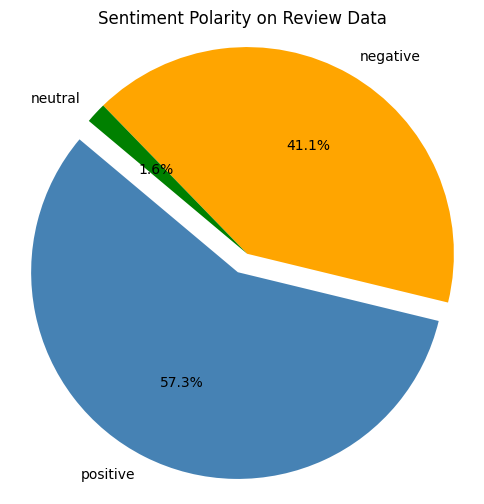

In [202]:
# Hitung jumlah sentimen secara otomatis
sentiment_counts = df['polarity'].value_counts()
plt.figure(figsize=(6, 6))

# Membuat tuple yang meledak berdasarkan jumlah sentimen
explode = tuple([0.1 if i == 0 else 0 for i in range(len(sentiment_counts))])

plt.pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['steelblue', 'orange', 'green', 'red', 'purple', 'brown'],  # More colors for more sentiments
    explode=explode
)
plt.title('Sentiment Polarity on Review Data')
plt.axis('equal')
plt.show()

In [203]:
df.to_csv('Hasil_Labelling_Data.csv', encoding='utf8', index = False); #Hasilnya di buat file

In [204]:
df.head()

,Review ID,Rating,Review Text,Date,Cleaned Review,text_clean,text_casefoldingText,text_slangwords,text_tokenizingText,text_stopword,text_akhir,polarity_score,polarity
0,cac788ca-6506-4451-9e70-4b84a66f9b8e,4,Instagram Tuti Wahyuni,09-04-2025,instagram tuti wahyuni,Instagram Tuti Wahyuni,instagram tuti wahyuni,instagram tuti wahyuni,"[instagram, tuti, wahyuni]","[instagram, tuti, wahyuni]",instagram tuti wahyuni,0,positive
1,6e67c75b-22f8-4774-892d-636e29808fd6,5,muhammad Ayib ALKAFF MUHAMM AYIB ALKAFF,09-04-2025,muhammad ayib alkaff muhamm ayib alkaff,muhammad Ayib ALKAFF MUHAMM AYIB ALKAFF,muhammad ayib alkaff muhamm ayib alkaff,muhammad ayib alkaff muhamm ayib alkaff,"[muhammad, ayib, alkaff, muhamm, ayib, alkaff]","[muhammad, ayib, alkaff, muhamm, ayib, alkaff]",muhammad ayib alkaff muhamm ayib alkaff,0,positive
2,b9ddaa0e-2f8f-4c8d-a68a-28003b48e1e6,1,tidak bisa login,09-04-2025,tidak bisa login,tidak bisa login,tidak bisa login,tidak bisa login,"[tidak, bisa, login]",[login],login,0,negative
3,731aa75e-821f-4851-8537-2c4e8282411c,5,Kenapa ig tdk bisa menginstal,09-04-2025,kenapa ig tidak bisa menginstal,Kenapa ig tdk bisa menginstal,kenapa ig tdk bisa menginstal,kenapa ig tidak bisa menginstal,"[kenapa, ig, tidak, bisa, menginstal]","[ig, menginstal]",ig menginstal,0,positive
4,6e978195-dda1-4ef4-965e-79e3bab15570,1,kenapa nyari filter gabisa tulisannya tidak da...,09-04-2025,kenapa mencari filter tidak bisa tulisannya ti...,kenapa nyari filter gabisa tulisannya tidak da...,kenapa nyari filter gabisa tulisannya tidak da...,kenapa mencari filter tidak bisa tulisannya ti...,"[kenapa, mencari, filter, tidak, bisa, tulisan...","[mencari, filter, tulisannya, da, hasil, naman...",mencari filter tulisannya da hasil namanya lia...,1,positive


# **WORDCLOUD**

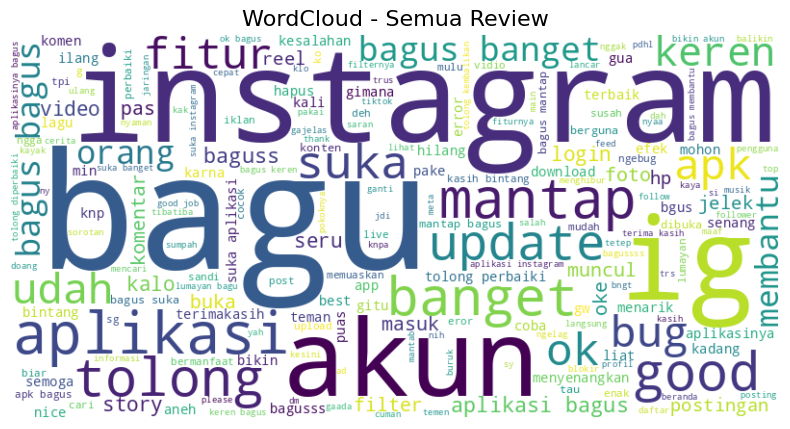

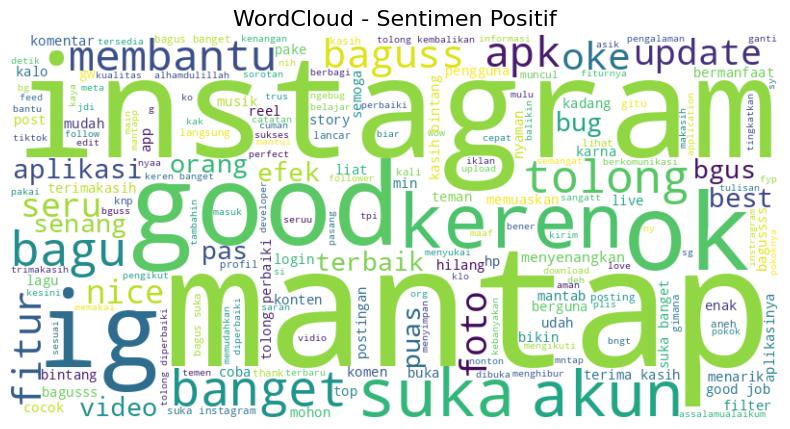

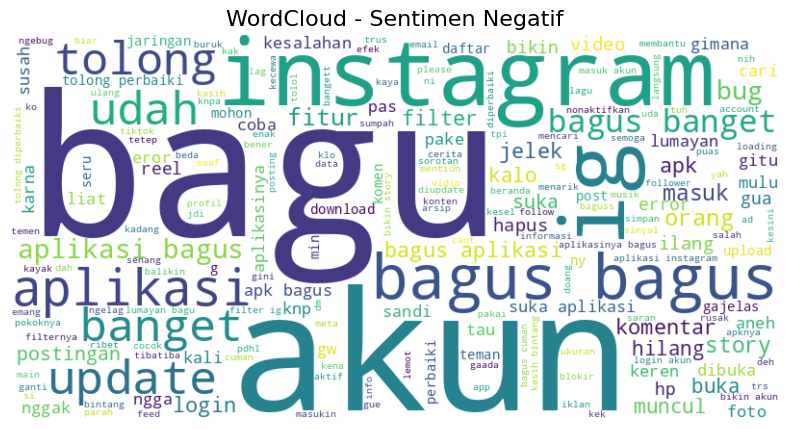

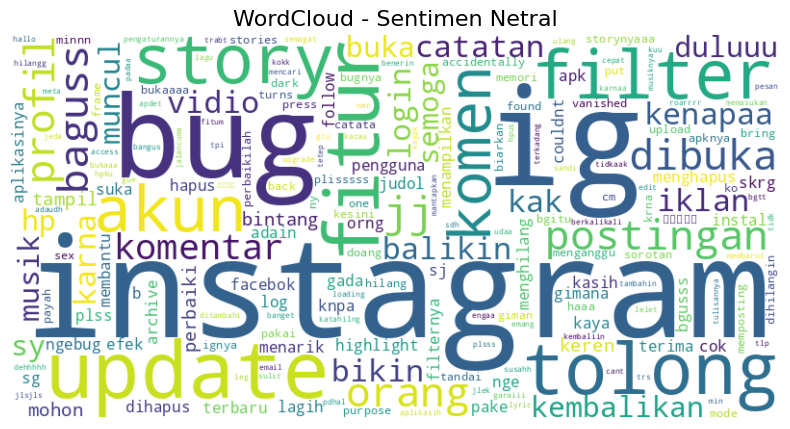

In [205]:
# Konversi kolom text_stopword dari string ke list (jika masih berbentuk string literal)
df['text_stopword'] = df['text_stopword'].apply(lambda x: eval(x) if isinstance(x, str) else x)

# Menggabungkan kata-kata berdasarkan polaritas
def get_words_by_sentiment(polarity_label):
    words = df[df['polarity'] == polarity_label]['text_stopword'].explode()
    return ' '.join(words.dropna().astype(str))

# Menghasilkan WordCloud
def generate_wordcloud(text, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title, fontsize=16)
    plt.axis('off')
    plt.show()

# Semua kategori
text_all = ' '.join(df['text_stopword'].explode().dropna().astype(str))
text_positive = get_words_by_sentiment('positive')
text_negative = get_words_by_sentiment('negative')
text_neutral = get_words_by_sentiment('neutral')

# Tampilkan semua WordCloud
generate_wordcloud(text_all, 'WordCloud - Semua Review')
generate_wordcloud(text_positive, 'WordCloud - Sentimen Positif')
generate_wordcloud(text_negative, 'WordCloud - Sentimen Negatif')
generate_wordcloud(text_neutral, 'WordCloud - Sentimen Netral')

# **DATA SPLITTING & EKSTRAKSI FEATURE**

In [206]:
# Pisahkan data menjadi fitur (tweet) dan label (sentimen)
X = df['text_akhir']
y = df['polarity']

# Ekstraksi fitur dengan TF-IDF
tfidf = TfidfVectorizer(max_features=200, min_df=17, max_df=0.8)
X_tfidf = tfidf.fit_transform(X)

# Konversi hasil ekstraksi fitur menjadi dataframe
features_df = pd.DataFrame(X_tfidf.toarray(), columns=tfidf.get_feature_names_out())

# Menampilkan hasil ekstraksi fitur
features_df

# Bagi data menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

# **MODELLING**

In [207]:
# Membuat objek model Naive Bayes (Bernoulli Naive Bayes)
naive_bayes = BernoulliNB()

# Melatih model Naive Bayes pada data pelatihan
naive_bayes.fit(X_train.toarray(), y_train)

# Prediksi sentimen pada data pelatihan dan data uji
y_pred_train_nb = naive_bayes.predict(X_train.toarray())
y_pred_test_nb = naive_bayes.predict(X_test.toarray())

# Evaluasi akurasi model Naive Bayes
accuracy_train_nb = accuracy_score(y_pred_train_nb, y_train)
accuracy_test_nb = accuracy_score(y_pred_test_nb, y_test)

# Menampilkan akurasi
print('Naive Bayes - accuracy_train:', accuracy_train_nb)
print('Naive Bayes - accuracy_test:', accuracy_test_nb)

Naive Bayes - accuracy_train: 0.824125
Naive Bayes - accuracy_test: 0.823


In [208]:
# Membuat objek model Random Forest
random_forest = RandomForestClassifier()

# Melatih model Random Forest pada data pelatihan
random_forest.fit(X_train.toarray(), y_train)

# Prediksi sentimen pada data pelatihan dan data uji
y_pred_train_rf = random_forest.predict(X_train.toarray())
y_pred_test_rf = random_forest.predict(X_test.toarray())

# Evaluasi akurasi model Random Forest
accuracy_train_rf = accuracy_score(y_pred_train_rf, y_train)
accuracy_test_rf = accuracy_score(y_pred_test_rf, y_test)

# Menampilkan akurasi
print('Random Forest - accuracy_train:', accuracy_train_rf)
print('Random Forest - accuracy_test:', accuracy_test_rf)

Random Forest - accuracy_train: 0.940375
Random Forest - accuracy_test: 0.8605


In [209]:
# Membuat objek model Logistic Regression
logistic_regression = LogisticRegression()

# Melatih model Logistic Regression pada data pelatihan
logistic_regression.fit(X_train.toarray(), y_train)

# Prediksi sentimen pada data pelatihan dan data uji
y_pred_train_lr = logistic_regression.predict(X_train.toarray())
y_pred_test_lr = logistic_regression.predict(X_test.toarray())

# Evaluasi akurasi model Logistic Regression pada data pelatihan
accuracy_train_lr = accuracy_score(y_pred_train_lr, y_train)

# Evaluasi akurasi model Logistic Regression pada data uji
accuracy_test_lr = accuracy_score(y_pred_test_lr, y_test)

# Menampilkan akurasi
print('Logistic Regression - accuracy_train:', accuracy_train_lr)
print('Logistic Regression - accuracy_test:', accuracy_test_lr)

Logistic Regression - accuracy_train: 0.879
Logistic Regression - accuracy_test: 0.871


In [210]:
# Membuat objek model Decision Tree
decision_tree = DecisionTreeClassifier()

# Melatih model Decision Tree pada data pelatihan
decision_tree.fit(X_train.toarray(), y_train)

# Prediksi sentimen pada data pelatihan dan data uji
y_pred_train_dt = decision_tree.predict(X_train.toarray())
y_pred_test_dt = decision_tree.predict(X_test.toarray())

# Evaluasi akurasi model Decision Tree
accuracy_train_dt = accuracy_score(y_pred_train_dt, y_train)
accuracy_test_dt = accuracy_score(y_pred_test_dt, y_test)

# Menampilkan akurasi
print('Decision Tree - accuracy_train:', accuracy_train_dt)
print('Decision Tree - accuracy_test:', accuracy_test_dt)

Decision Tree - accuracy_train: 0.940375
Decision Tree - accuracy_test: 0.8405


In [211]:
# Ambil hanya kolom yang diperlukan
# df_ml = df_rnn[['Review Text', 'Rating']].copy() # Original line causing the error
df_ml = df[['Review Text', 'Rating']].copy() # Replace df_rnn with df
df_ml.dropna(inplace=True)

# Label sentimen dari rating
def label_sentiment(rate):
    if rate >= 4:
        return 'positive'
    elif rate == 3:
        return 'neutral'
    else:
        return 'negative'

df_ml['sentiment'] = df_ml['Rating'].apply(label_sentiment)

# Preprocessing dasar
df_ml['clean_text'] = df_ml['Review Text'].astype(str).str.lower()

# TF-IDF Feature Extraction
tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf_vectorizer.fit_transform(df_ml['clean_text'])

# Tokenize untuk Word2Vec
df_ml['tokens'] = df_ml['clean_text'].apply(lambda x: x.split())

# Train Word2Vec model
w2v_model = Word2Vec(sentences=df_ml['tokens'], vector_size=100, window=5, min_count=1, workers=4)
word_vectors = w2v_model.wv

# Rata-rata vector untuk tiap review
def get_average_w2v(tokens):
    vectors = [word_vectors[word] for word in tokens if word in word_vectors]
    return np.mean(vectors, axis=0) if vectors else np.zeros(100)

X_w2v = np.vstack(df_ml['tokens'].apply(get_average_w2v))

# Encode label
y = df_ml['sentiment']

# Percobaan 1: SVM + TF-IDF + 80/20
X_train1, X_test1, y_train1, y_test1 = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)
model1 = SVC()
model1.fit(X_train1, y_train1)
pred1 = model1.predict(X_test1)
report1 = classification_report(y_test1, pred1, output_dict=True)

# Percobaan 2: RF + Word2Vec + 80/20
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_w2v, y, test_size=0.2, random_state=42)
model2 = RandomForestClassifier()
model2.fit(X_train2, y_train2)
pred2 = model2.predict(X_test2)
report2 = classification_report(y_test2, pred2, output_dict=True)

# Percobaan 3: RF + TF-IDF + 70/30
X_train3, X_test3, y_train3, y_test3 = train_test_split(X_tfidf, y, test_size=0.3, random_state=42)
model3 = RandomForestClassifier()
model3.fit(X_train3, y_train3)
pred3 = model3.predict(X_test3)
report3 = classification_report(y_test3, pred3, output_dict=True)

# Use this:
results_df = pd.DataFrame({
    'Percobaan': ['SVM + TF-IDF (80/20)', 'RF + Word2Vec (80/20)', 'RF + TF-IDF (70/30)'],
    'Akurasi': [report1['accuracy'], report2['accuracy'], report3['accuracy']],
    'F1-score (Macro)': [
        classification_report(y_test1, pred1, output_dict=True, zero_division=0)['macro avg']['f1-score'],
        classification_report(y_test2, pred2, output_dict=True, zero_division=0)['macro avg']['f1-score'],
        classification_report(y_test3, pred3, output_dict=True, zero_division=0)['macro avg']['f1-score']
    ]
})
print("Hasil Evaluasi 3 Percobaan")
display(results_df)

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Hasil Evaluasi 3 Percobaan


,Percobaan,Akurasi,F1-score (Macro)
0,SVM + TF-IDF (80/20),0.840500,0.541974
1,RF + Word2Vec (80/20),0.798000,0.499748
2,RF + TF-IDF (70/30),0.833333,0.534843


# **INFERENCE**

In [212]:
# Contoh input review baru untuk diuji
new_reviews = [
    "Aplikasinya sangat bagus dan sangat membantu",
    "Banyak error dan sering force close",
    "Ya lumayan lah untuk versi awal",
    "Susah login dan fitur sering tidak muncul",
    "Saya suka tampilannya, simpel dan cepat"
]

# 1. Preprocessing (lowercase)
new_reviews_clean = [text.lower() for text in new_reviews]

# 2. Transform ke TF-IDF
new_reviews_tfidf = tfidf_vectorizer.transform(new_reviews_clean)

# 3. Prediksi menggunakan model RF + TF-IDF (model3)
predictions = model3.predict(new_reviews_tfidf)

# 4. Tampilkan hasil
for review, pred in zip(new_reviews, predictions):
    print(f"Review: {review}")
    print(f"Prediksi Sentimen: {pred}")
    print("-" * 60)

Review: Aplikasinya sangat bagus dan sangat membantu
Prediksi Sentimen: positive
------------------------------------------------------------
Review: Banyak error dan sering force close
Prediksi Sentimen: positive
------------------------------------------------------------
Review: Ya lumayan lah untuk versi awal
Prediksi Sentimen: positive
------------------------------------------------------------
Review: Susah login dan fitur sering tidak muncul
Prediksi Sentimen: negative
------------------------------------------------------------
Review: Saya suka tampilannya, simpel dan cepat
Prediksi Sentimen: positive
------------------------------------------------------------
